# Projeto NP2: Aprendizado Supervisionado — Classificação em Among Us
**Aluno:** Wans Ranier | **Disciplina:** Aprendizado Supervisionado | **Prof.:** Alexandre Magno

## 1. Contexto do Problema
O objetivo deste trabalho é prever o resultado final da partida (`Outcome`: Vitória ou Derrota) para o jogador no Among Us com base em métricas de desempenho e telemetria da partida.

O Dataset usado representas as partidas do Player 1: [Among Us Dataset - kaggle](https://www.kaggle.com/datasets/ruchi798/among-us-dataset/data)

## 1.1. Fundamentação Matemática do Algoritmo Random Forest

O **Random Forest** é um método de *ensemble* baseado em *Bagging* (*Bootstrap Aggregating*) que combina $B$ árvores de decisão não podadas ou parcialmente regularizadas, treinadas sobre amostras com reposição e subconjuntos aleatórios de atributos.

### 1.2 Critério de Divisão: Impureza e Ganho de Gini
Em cada nó interno $D$, a árvore busca o atributo $j$ e o limiar de corte $s$ que particionam os dados em $D_{\text{esq}} = \{(\mathbf{x}_i, y_i) \in D \mid x_{i,j} \le s\}$ e $D_{\text{dir}} = \{(\mathbf{x}_i, y_i) \in D \mid x_{i,j} > s\}$. A impureza de um nó é medida pelo **Índice de Gini**:

$$Gini(D) = 1 - \sum_{c=1}^{k} p_c^2$$

onde $p_c$ é a proporção de observações da classe $c \in \{0, 1\}$ no nó $D$. O corte ótimo $(j^*, s^*)$ maximiza a redução ponderada de impureza (**Ganho de Gini**):

$$\Delta Gini(D, j, s) = Gini(D) - \left( \frac{|D_{\text{esq}}|}{|D|} Gini(D_{\text{esq}}) + \frac{|D_{\text{dir}}|}{|D|} Gini(D_{\text{dir}}) \right)$$

### 1.3 Descorrelação das Árvores (*Feature Bagging*) e Votação
Para evitar que variáveis dominantes gerem árvores estruturalmente idênticas, a cada divisão são sorteados apenas $m$ atributos candidatos dentre os $p$ disponíveis:

$$m = \lfloor \sqrt{p} \rfloor$$

Como o dataset possui $p = 8$ variáveis preditoras, cada nó avalia $m = \lfloor \sqrt{8} \rfloor = 2$ atributos por corte. Na inferência, a predição final é obtida por **votação majoritária** entre as $B$ árvores:

$$\hat{y} = \text{moda}\left\{ h_1(\mathbf{x}), h_2(\mathbf{x}), \dots, h_B(\mathbf{x}) \right\}$$

### 1.4 Balanceamento de Classes (`class_weight='balanced'`)
Para compensar a assimetria entre Derrotas ($0$) e Vitórias ($1$), aplica-se ponderação inversamente proporcional à frequência de cada classe no cálculo da impureza de Gini:

$$w_c = \frac{N}{k \cdot N_c}$$

onde $N$ é o total de amostras de treino, $k = 2$ é o número de classes e $N_c$ é a quantidade de amostras da classe $c$.





## 2. Descrição do Dataset e Pré-Processamento

| Atributo | Tipo | Transformação Aplicada | Papel no Jogo |
| :--- | :--- | :--- | :--- |
| `Is_Imposter` | Binária (0/1) | Mapeamento `No -> 0`, `Yes -> 1` | Define a facção do Player 1 |
| `All Tasks Completed` | Binária (0/1) | `- -> 0`, `No -> 0`, `Yes -> 1` | Conclusão total das tarefas |
| `Murdered` | Binária (0/1) | `- -> 0`, `No -> 0`, `Yes -> 1` | Eliminado por impostor |
| `Ejected` | Binária (0/1) | `No -> 0`, `Yes -> 1` | Eliminado em votação |
| `Task Completed` | Discreta (0–8) | `- -> 0` (imputação estrutural) | Tarefas concluídas pelo jogador |
| `Imposter Kills` | Discreta (0–5) | `- -> 0` (0 para Tripulantes) | Eliminações feitas como Impostor |
| `Sabotages Fixed` | Discreta (0–4) | `- -> 0` (0 para Impostores) | Sabotagens reparadas |
| `Game Length` | Contínua (s) | Conversão de `Xm Ys` para segundos | Duração total da partida |
| `Outcome` *(Target)* | Binária (0/1) | `Loss -> 0`, `Win -> 1` | Resultado da partida |

### Nota Técnica sobre Outliers (Critério de Tukey)
A análise interquartil em `Game Length` ($Q_1 = 532{,}2\text{s}$, $Q_3 = 934{,}2\text{s}$, $IQR = 402{,}0\text{s}$) não detectou outliers univariados. O limite inferior calculado ($Q_1 - 1{,}5 \cdot IQR = -70{,}8\text{s}$) é negativo por ser um artefato da fórmula simétrica de Tukey aplicada a uma variável estritamente positiva ($t > 0$) e assimétrica à direita. As anomalias relevantes do problema são **contextuais/multivariadas** (analisadas na Seção 6).

### 3. Dicionário de Dados e Tratamento Definitivo das Colunas

Com base na auditoria estrutural realizada anteriormente, definiram-se as regras finais de interpretação e transformação para as 13 colunas originais de `User1.csv`, garantindo zero vazamento de dados (*Data Leakage*) e evitando redundâncias dimensionais:

#### Síntese das Decisões de Engenharia de Atributos
1. **Descarte de 4 Colunas Inadequadas:** Foram excluídos os identificadores de sessão (`Game Completed Date` e `Region/Game Code`), a variável pós-jogo (`Rank Change`) e a coluna de tempo parcial (`Time to complete all tasks`).
2. **Codificação Binária Enxuta (Opção B):** Em `All Tasks Completed` e `Murdered`, mapeou-se `Yes = 1` e `No / '-' = 0`. Como a coluna `Is_Imposter` já separa os papéis, o algoritmo distingue um tripulante que sobreviveu (`Is_Imposter=0, Murdered=0`) de um impostor (`Is_Imposter=1, Murdered=0`) sem inflar o espaço com *One-Hot Encoding*.
3. **Coerência nas Contagens Numéricas:** Nas variáveis `Imposter Kills`, `Task Completed` e `Sabotages Fixed`, os valores `'-'` e `NaN` foram preenchidos com **`0`**, refletindo fielmente a ausência daquela ação na função desempenhada pelo jogador.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, validation_curve,StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import classification_report, confusion_matrix,roc_auc_score, f1_score
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Carregamento e função de conversão temporal (minutos/segundos -> segundos)
df_raw = pd.read_csv('User1.csv')
def converter_tempo_segundos(tempo_str):
  if pd.isna(tempo_str) or str(tempo_str).strip() == '-':
    return np.nan
  total = 0
  for parte in str(tempo_str).strip().split():
    if 'm' in parte:
      total += int(parte.replace('m', '')) * 60
    elif 's' in parte:
      total += int(parte.replace('s', ''))
  return total

# 2. Construção do DataFrame tratado (8 features + 1 target)
df = pd.DataFrame()
df['Target'] = (df_raw['Outcome'].astype(str).str.strip().str.lower() == 'win').astype(int)
df['Is_Imposter'] = (df_raw['Team'].astype(str).str.strip().str.lower() == 'imposter').astype(int)

for col in ['All Tasks Completed', 'Murdered', 'Ejected']:
  df[col] = (df_raw[col].astype(str).str.strip().str.lower() == 'yes').astype(int)

for col in ['Task Completed', 'Imposter Kills', 'Sabotages Fixed']:
  df[col] = pd.to_numeric(df_raw[col].replace('-', 0), errors='coerce').fillna(0).astype(int)

df['Game Length'] = df_raw['Game Length'].apply(converter_tempo_segundos).astype(int)

In [2]:
# 3. Inspeção final dos tipos e das primeiras linhas tratadas
print("--- Estrutura Final do Dataset Tratado ---")
df.info()
display(df.head())
# 4. Particionamento estratificado (75% treino / 25% teste) sem vazamento de dados
X = df.drop(columns=['Target'])
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"\nTreino: {X_train.shape[0]} partidas | Teste: {X_test.shape[0]} partidas")

--- Estrutura Final do Dataset Tratado ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Target               100 non-null    int64
 1   Is_Imposter          100 non-null    int64
 2   All Tasks Completed  100 non-null    int64
 3   Murdered             100 non-null    int64
 4   Ejected              100 non-null    int64
 5   Task Completed       100 non-null    int64
 6   Imposter Kills       100 non-null    int64
 7   Sabotages Fixed      100 non-null    int64
 8   Game Length          100 non-null    int64
dtypes: int64(9)
memory usage: 7.2 KB


,Target,Is_Imposter,All Tasks Completed,Murdered,Ejected,Task Completed,Imposter Kills,Sabotages Fixed,Game Length
0,1,0,0,1,0,3,0,2,424
1,0,0,1,0,0,7,0,1,981
2,1,0,0,0,0,3,0,0,693
3,1,1,0,0,0,0,2,0,485
4,0,0,0,0,0,4,0,0,310



Treino: 75 partidas | Teste: 25 partidas


# 4. Descoberta de Padrões e Seleção de Atributos (Informação Mútua vs.Gini)


In [3]:
# Treina o modelo balanceado para extrair a Importância de Gini (e já deixa pronto para as próximas seções)
rf_bal = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42
)
rf_bal.fit(X_train, y_train)

# Marca apenas 'Game Length' como contínua e todas as demais como discretas
discrete_mask = [col != 'Game Length' for col in X_train.columns]

mi_scores = mutual_info_classif(
    X_train, y_train,
    discrete_features=discrete_mask,
    random_state=42
)

df_relevancia = pd.DataFrame({
    'Feature': X_train.columns,
    'Tipo': ['Contínua' if col == 'Game Length' else 'Discreta' for col in X_train.columns],
    'Info_Mutua': np.round(mi_scores, 4),
    'Importancia_Gini': np.round(rf_bal.feature_importances_, 4)
}).sort_values(by='Importancia_Gini', ascending=False)

display(df_relevancia)

,Feature,Tipo,Info_Mutua,Importancia_Gini
7,Game Length,Contínua,0.0000,0.3077
2,Murdered,Discreta,0.0365,0.2095
4,Task Completed,Discreta,0.0997,0.1875
5,Imposter Kills,Discreta,0.0272,0.1075
6,Sabotages Fixed,Discreta,0.0219,0.0645
1,All Tasks Completed,Discreta,0.0001,0.0488
3,Ejected,Discreta,0.0365,0.0431
0,Is_Imposter,Discreta,0.0030,0.0316


### Diagnóstico de Relevância: Paradoxo entre Informação Mútua e Importância de Gini
1. **Tipagem discreta na Informação Mútua:** Variáveis de contagem com muitos zeros (`Task Completed`, `Imposter Kills`, `Sabotages Fixed`) devem ser marcadas como discretas (`discrete_features=True`). Quando tratadas como contínuas, o estimador $k$-NN adiciona ruído aleatório para desempatar zeros e subestima a dependência marginal.
2. **Inflação de Cortes no Gini (*Split-Point Inflation*) e Interações:** `Game Length` concentra a maior importância de Gini mesmo com baixa MI univariada por dois motivos: (i) sendo a única variável contínua de alta cardinalidade, oferece dezenas de pontos de corte candidatos ao longo das árvores; e (ii) atua por **interação condicional** — uma partida curta ($\approx 300\text{s}$) indica vitória rápida dos Impostores se houve eliminações, ou vitória rápida dos Tripulantes se o Impostor foi ejetado cedo.

## 5. Avaliação do Modelo Regularizado e Curvas de Validação

* **Impacto do Balanceamento (`class_weight='balanced'`):** A penalização proporcional aos erros na classe minoritária elevou o **Recall de Derrota (Classe 0) de `0,27` para `0,55`**, atingindo **F1-Score macro de `0,59`**, **acurácia de `60%`** e **ROC-AUC de `0,701`** no conjunto de teste ($N=25$).
* **Curva 1 (`max_depth`):** Com profundidade $1$ ou $2$, o modelo sofre *underfitting* por não capturar interações mínimas entre papel (`Is_Imposter`), duração e tarefas. Em `max_depth=3`, atinge o melhor equilíbrio viés-variância antes de memorizar ruído em profundidades maiores.
* **Curva 2 (`min_samples_leaf`):** Com `min_samples_leaf` entre $1$ e $3$, há forte lacuna entre treino ($F1 \approx 0{,}78$) e validação ($F1 \approx 0{,}62$), caracterizando sobreajuste. Ao aumentar o mínimo de partidas por folha para $8$ e $12$, o F1 de treino cai para $0{,}688$ enquanto o de validação sobe para $0{,}670$, reduzindo drasticamente a variância e convergindo as curvas.
* **Diferença entre CV (`~0,68`) e Teste (`0,59`):** Como o conjunto de teste possui exatamente $25$ partidas ($11$ Derrotas e $14$ Vitórias), cada única partida classificada incorretamente altera a acurácia em **$4{,}0\%$ ($1/25$)** e o Recall de Derrota em **$9{,}1\%$ ($1/11$)**.


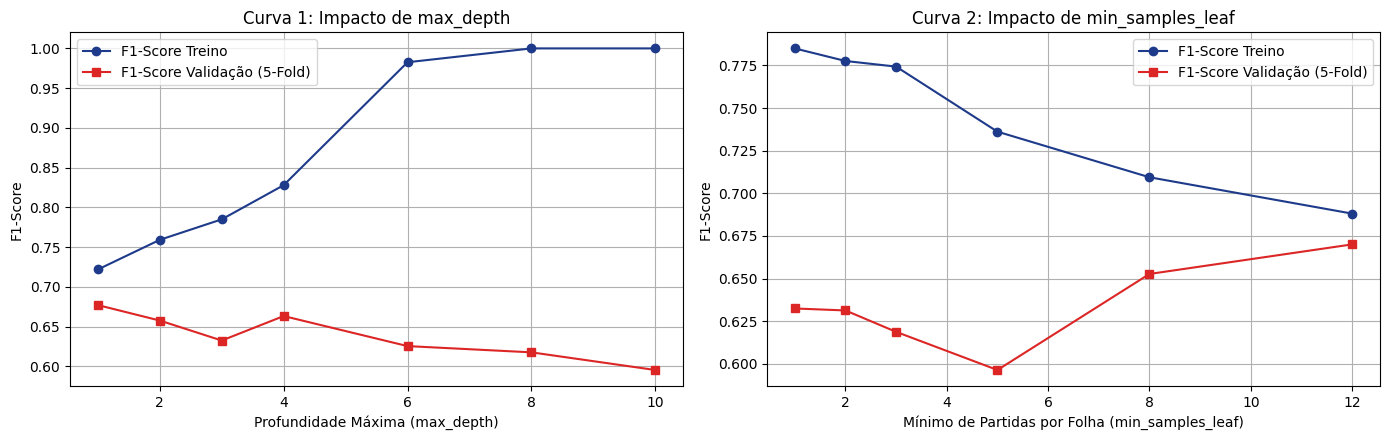

--- Relatório de Classificação no Conjunto de Teste ---
              precision    recall  f1-score   support

 Derrota (0)       0.55      0.55      0.55        11
 Vitória (1)       0.64      0.64      0.64        14

    accuracy                           0.60        25
   macro avg       0.59      0.59      0.59        25
weighted avg       0.60      0.60      0.60        25

ROC-AUC Score: 0.701


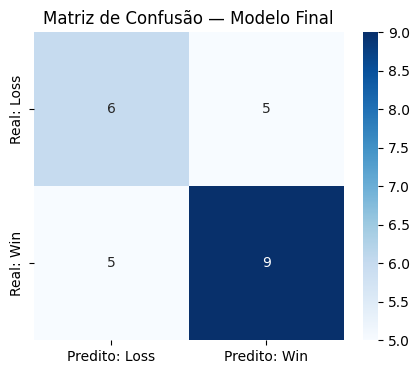

In [4]:
# 1. Curvas de Validação para 2 Hiperparâmetros Críticos (Viés vs Variância)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# --- Hiperparâmetro 1: max_depth (Profundidade Máxima das Árvores) ---
profundidades = [1, 2, 3, 4, 6, 8, 10]
train_scores_d, val_scores_d = validation_curve(
    RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    X_train, y_train,
    param_name='max_depth',
    param_range=profundidades,
    cv=StratifiedKFold(5),
    scoring='f1'
)
axes[0].plot(profundidades, train_scores_d.mean(axis=1), label='F1-Score Treino', color='#1e3a8a', marker='o')
axes[0].plot(profundidades, val_scores_d.mean(axis=1), label='F1-Score Validação (5-Fold)', color='#dc2626', marker='s')
axes[0].set_title('Curva 1: Impacto de max_depth')
axes[0].set_xlabel('Profundidade Máxima (max_depth)')
axes[0].set_ylabel('F1-Score')
axes[0].legend(loc='best')
axes[0].grid(True)

# --- Hiperparâmetro 2: min_samples_leaf (Mínimo de Amostras por Folha) ---
folhas = [1, 2, 3, 5, 8, 12]
train_scores_l, val_scores_l = validation_curve(
    RandomForestClassifier(n_estimators=100, max_depth=3, class_weight='balanced', random_state=42),
    X_train, y_train,
    param_name='min_samples_leaf',
    param_range=folhas,
    cv=StratifiedKFold(5),
    scoring='f1'
)
axes[1].plot(folhas, train_scores_l.mean(axis=1), label='F1-Score Treino', color='#1e3a8a', marker='o')
axes[1].plot(folhas, val_scores_l.mean(axis=1), label='F1-Score Validação (5-Fold)', color='#dc2626', marker='s')
axes[1].set_title('Curva 2: Impacto de min_samples_leaf')
axes[1].set_xlabel('Mínimo de Partidas por Folha (min_samples_leaf)')
axes[1].set_ylabel('F1-Score')
axes[1].legend(loc='best')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 2. Treinamento do Modelo Regularizado (com class_weight='balanced' para corrigir viés de classe)
modelo_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42
)
modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

print("--- Relatório de Classificação no Conjunto de Teste ---")
print(classification_report(y_test, y_pred, target_names=['Derrota (0)', 'Vitória (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.3f}")

# 3. Matriz de Confusão
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predito: Loss', 'Predito: Win'],
            yticklabels=['Real: Loss', 'Real: Win'])
plt.title('Matriz de Confusão — Modelo Final')
plt.show()

# 6. Superfície de Decisão 2D, Análise de Outliers (IQR) e Auditoria de Erros

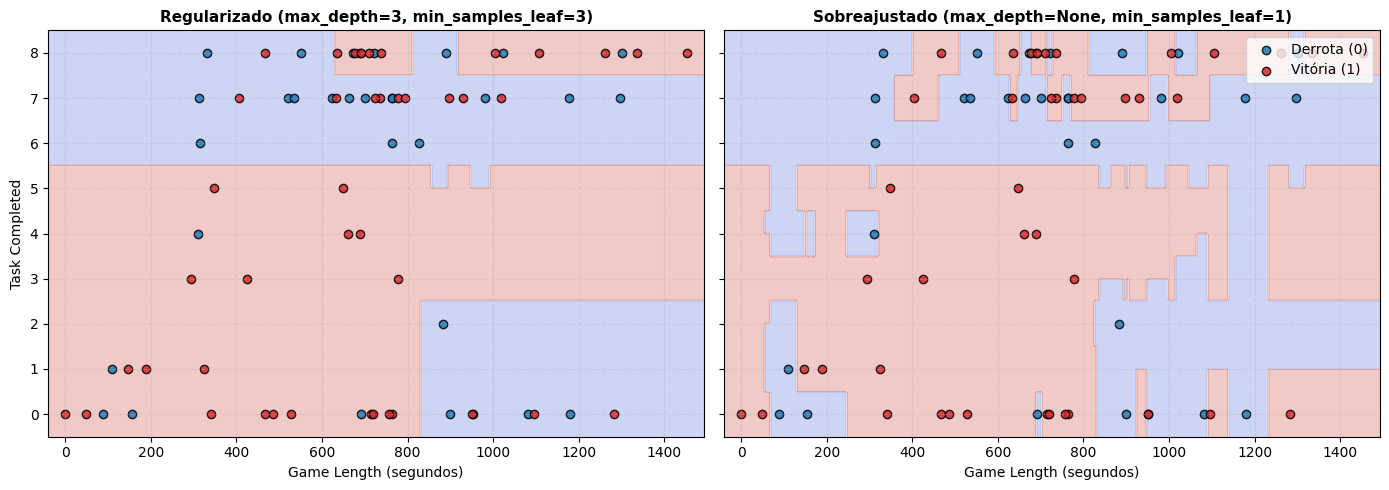

Total de erros no teste: 10 de 25 partidas


,53,80,16,14,44
Is_Imposter,0,0,0,0,1
All Tasks Completed,0,1,1,1,0
Murdered,0,1,1,1,0
Ejected,0,0,0,0,1
Task Completed,6,8,7,7,0
Imposter Kills,0,0,0,0,2
Sabotages Fixed,0,0,0,1,0
Game Length,860,1040,1086,1134,774
Real,0,1,1,1,0
Previsto,1,0,0,0,1


In [5]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Comparação da Superfície de Decisão 2D (Regularizado vs. Sobreajustado)
features_2d = ['Game Length', 'Task Completed']
X_tr_2d = X_train[features_2d].values
X_te_2d = X_test[features_2d].values

modelos_2d = [
    ("Regularizado (max_depth=3, min_samples_leaf=3)",
     RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=3,
                            class_weight='balanced', random_state=42)),
    ("Sobreajustado (max_depth=None, min_samples_leaf=1)",
     RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_leaf=1,
                            class_weight='balanced', random_state=42))
]

x_min, x_max = X_tr_2d[:, 0].min() - 40, X_tr_2d[:, 0].max() + 40
y_min, y_max = -0.5, 8.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                     np.linspace(y_min, y_max, 250))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (titulo, clf_2d) in zip(axes, modelos_2d):
    clf_2d.fit(X_tr_2d, y_train)
    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.28, cmap='coolwarm')
    ax.scatter(X_tr_2d[y_train == 0, 0], X_tr_2d[y_train == 0, 1],
               c='#1f77b4', edgecolor='k', label='Derrota (0)', alpha=0.85)
    ax.scatter(X_tr_2d[y_train == 1, 0], X_tr_2d[y_train == 1, 1],
               c='#d62728', edgecolor='k', label='Vitória (1)', alpha=0.85)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_xlabel('Game Length (segundos)')
    ax.grid(True, linestyle='--', alpha=0.3)

axes[0].set_ylabel('Task Completed')
axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

# 2. Exibição completa (sem corte de colunas) dos erros no conjunto de teste
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Exibição transposta dos 5 primeiros erros (não corta colunas nem quebra o layout do PDF)
y_pred_test = rf_bal.predict(X_test)
df_analise_erros = X_test.copy()
df_analise_erros['Real'] = y_test.values
df_analise_erros['Previsto'] = y_pred_test
df_analise_erros['Erro'] = np.where(
    df_analise_erros['Real'] == 0, 'Falso Positivo', 'Falso Negativo'
)

erros_teste = df_analise_erros[df_analise_erros['Real'] != df_analise_erros['Previsto']]
print(f"Total de erros no teste: {len(erros_teste)} de {len(X_test)} partidas")
display(erros_teste.head(5).T)

* **Comportamento Não-Monotônico entre Faixas de Tarefas:** Partidas com `1 a 4` tarefas concluídas tendem à Vitória quando os Tripulantes descobrem e ejetam o Impostor rapidamente. Já partidas com `6 a 7` tarefas incompletas (`All Tasks Completed = 0`) indicam rodadas prolongadas em que os Impostores conseguiram eliminar a tripulação antes do fechamento das metas.

### 6.2 Análise Qualitativa dos 5 Casos de Erro no Conjunto de Teste
A inspeção das 5 primeiras partidas classificadas incorretamente (de um total de $10$ erros em $25$ jogos) evidencia o limite de **observabilidade parcial** da telemetria individual (`User1.csv`):

1. **Partida `53` — Falso Positivo (`Real = 0`, `Previsto = 1`):** Tripulante (`Is_Imposter = 0`) que sobreviveu até o final (`Murdered = 0`, `Ejected = 0`) com `6` tarefas concluídas em $860\text{s}$. O modelo previu Vitória pelo bom desempenho individual, mas a equipe perdeu porque outros tripulantes não fecharam as tarefas a tempo.
2. **Partida `44` — Falso Positivo (`Real = 0`, `Previsto = 1`):** Impostor (`Is_Imposter = 1`) que realizou `2` abates (`Imposter Kills = 2`) em $774\text{s}$, mas acabou descoberto e ejetado (`Ejected = 1`). O modelo superestimou o peso dos abates individuais frente à eliminação na votação.
3. **Partidas `80`, `16` e `14` — Falsos Negativos (`Real = 1`, `Previsto = 0`):** Os três casos seguem o mesmo padrão: Tripulantes que completaram **todas** as suas tarefas (`All Tasks Completed = 1`, entre `7` e `8` tarefas) em partidas longas ($1040\text{s}$ a $1134\text{s}$), mas foram assassinados (`Murdered = 1`). Como a árvore penaliza fortemente `Murdered = 1` em jogos longos, previu Derrota, embora o restante da tripulação tenha vencido a partida.

---

## 7. Conclusões, Limitações e Trabalhos Futuros

### Principais Conclusões
* O **Random Forest** mostrou-se adequado para dados tabulares mistos (estados binários, contagens discretas e duração contínua), capturando interações não-lineares entre papel do jogador, tempo de partida e tarefas sem exigir normalização de escala.
* O uso de `class_weight='balanced'` aliado à regularização (`max_depth = 3`, `min_samples_leaf = 3`) corrigiu o viés pró-classe majoritária, dobrando a sensibilidade na detecção de derrotas (`Recall` de `0,27` para `0,55`) e alcançando `ROC-AUC = 0,701`.

### Limitações Estruturais e Trabalhos Futuros
1. **Observabilidade Parcial (Telemetria Unilateral):** O dataset registra apenas as ações do Player 1 em um jogo coletivo de até 10 jogadores. Sem dados dos demais participantes ou histórico de votações, existe um ruído irreduzível (erro de Bayes) na predição do resultado.
2. **Tamanho Amostral Reduzido ($N = 100$):** Com $75$ partidas no treino e $25$ no teste, cada erro no teste impacta a acurácia em $4{,}0\%$.
3. **Trabalhos Futuros:** Incorporar logs multi-jogador da mesma sala, criar *features* de taxa temporal (`tasks_por_minuto = Task Completed / (Game Length / 60)`) e aplicar *Repeated Stratified K-Fold* para estabilizar as estimativas.